# Diagnóstico y evaluación del escenario geoespacial

Este notebook responde tres preguntas:

1. **¿Están alineados** `airprice_clean.csv` y `airprice_features.csv`? (mismo orden de filas, mismo target, mismo split).
2. **¿Cuánto aportan** las features geoespaciales? (importancia agregada, información mutua, correlación ordinal y ablación con/sin geo).
3. **¿Cómo rinden** los 4 modelos con geo? (consolidación de `reports/*_features_metricas.csv` y comparación contra base).

Ejecutar después de los 4 notebooks de `notebooks/models_features/`.

In [2]:
import sys
sys.path.append('../..')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

from src.etl_features_ext import LISTINGS_PATH
from src.model_features import PARAMS_BASE, construir_lgbm_features, evaluar_modelo_ordinal
from src.preprocessing_features import (
    FEATURES_PATH,
    cargar_features,
    columnas_geo,
    preparar_dataset_features,
)
from src.utils import (
    CLEAN_PATH,
    CLASES,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    split_estratificado,
)

sns.set_theme(style='whitegrid')
fijar_semilla(SEED)
print('Semilla:', SEED)

Semilla: 42


In [3]:
clean = cargar_dataset(CLEAN_PATH)
feats = cargar_features(FEATURES_PATH)

print('Clean:', clean.shape, 'Features:', feats.shape)
print('Mismo orden de id:', clean['id'].equals(feats['id']))
print('Mismo target:', clean['price_range'].equals(feats['price_range']))
print('Mismo orden de columnas base:', list(clean.columns) == list(feats.columns[:len(clean.columns)]))

_, _, _, y_train_clean, y_val_clean, y_test_clean = split_estratificado(
    clean, target='price_range', excluir=['price_clean', 'id'], seed=SEED
)
_, _, _, y_train_geo, y_val_geo, y_test_geo = split_estratificado(
    feats, target='price_range', excluir=['price_clean', 'id'], seed=SEED
)
print('Mismo split train:', y_train_clean.equals(y_train_geo))
print('Mismo split val:', y_val_clean.equals(y_val_geo))
print('Mismo split test:', y_test_clean.equals(y_test_geo))

Clean: (61617, 32) Features: (61617, 38)
Mismo orden de id: True
Mismo target: True
Mismo orden de columnas base: True
Mismo split train: True
Mismo split val: True
Mismo split test: True


In [4]:
VERIFICAR_IDS = True
if VERIFICAR_IDS:
    ids_original = pd.read_csv(LISTINGS_PATH, usecols=['id'])['id']
    tasa = float(feats['id'].isin(ids_original).mean())
    print('IDs de features presentes en listings.csv:', round(tasa, 6))
    print('IDs únicos en features:', feats['id'].nunique(), 'de', len(feats))
else:
    print('Verificación de IDs omitida. Se espera una tasa de 1.0: el clean se derivó del listings.csv.')

IDs de features presentes en listings.csv: 1.0
IDs únicos en features: 61617 de 61617


In [5]:
df = preparar_dataset_features(feats)
X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target='price_range',
    excluir=['price_clean', 'id'],
    seed=SEED,
)
geo = [c for c in columnas_geo(X_train) if c in X_train.columns]
print('Features geo:', geo)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

Features geo: ['distancia_centro_km', 'distancia_heathrow_km', 'distancia_kings_cross_km', 'distancia_hyde_park_km', 'distancia_canary_wharf_km', 'cluster_zona']
Train: (43131, 28) Val: (9243, 28) Test: (9243, 28)


,variable,mutual_info
0,distancia_hyde_park_km,0.119690
1,distancia_centro_km,0.104151
2,distancia_kings_cross_km,0.089768
3,distancia_heathrow_km,0.084622
4,distancia_canary_wharf_km,0.060742
5,cluster_zona,0.020567


C:\Users\user\AppData\Local\Temp\ipykernel_5064\2392723195.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=mi_df, x='mutual_info', y='variable', palette='viridis')


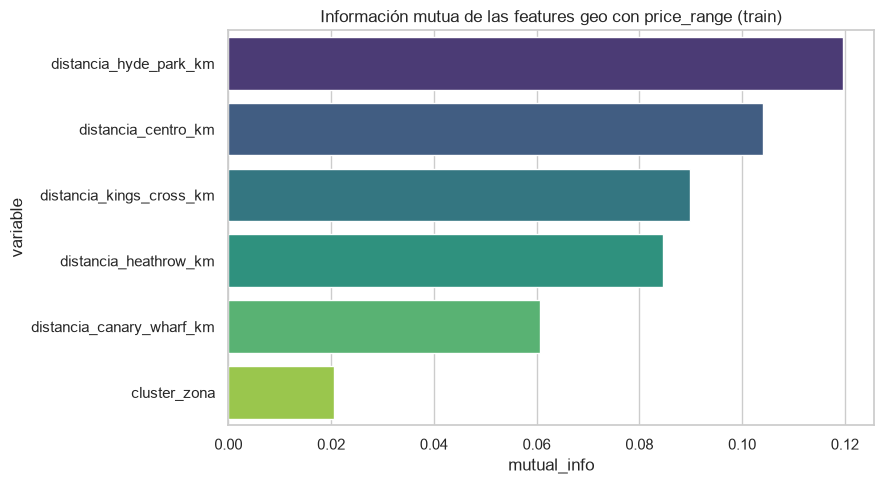

In [6]:
info_mutua = mutual_info_classif(
    X_train[geo], y_train, random_state=SEED
)
mi_df = (
    pd.DataFrame({'variable': geo, 'mutual_info': info_mutua})
    .sort_values('mutual_info', ascending=False)
    .reset_index(drop=True)
)
mi_df.to_csv(REPORTS_DIR / 'features_mutual_info.csv', index=False)

display(mi_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=mi_df, x='mutual_info', y='variable', palette='viridis')
plt.title('Información mutua de las features geo con price_range (train)')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'features_mutual_info.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
mapa = {clase: i for i, clase in enumerate(CLASES)}
y_ordinal = y_train.map(mapa)
correlaciones = X_train[geo].corrwith(y_ordinal, method='spearman')
corr_df = (
    correlaciones.rename('spearman_con_target')
    .to_frame()
    .sort_values('spearman_con_target', ascending=False)
)
corr_df.to_csv(REPORTS_DIR / 'features_correlacion.csv')
display(corr_df)

,spearman_con_target
cluster_zona,0.181463
distancia_canary_wharf_km,-0.095070
distancia_heathrow_km,-0.142017
distancia_kings_cross_km,-0.324690
distancia_centro_km,-0.378646
distancia_hyde_park_km,-0.402481


es_geo,False,True,aporte_geo_pct
modelo,,,
lightgbm,17924.000000,6876.000000,27.725806
ordinal_logistic,34.917487,7.533215,17.745797
random_forest,0.721545,0.278455,27.845545
xgboost,0.933309,0.066691,6.669136


C:\Users\user\AppData\Local\Temp\ipykernel_5064\3047292013.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_geo.values, y=top_geo.index, palette='mako')


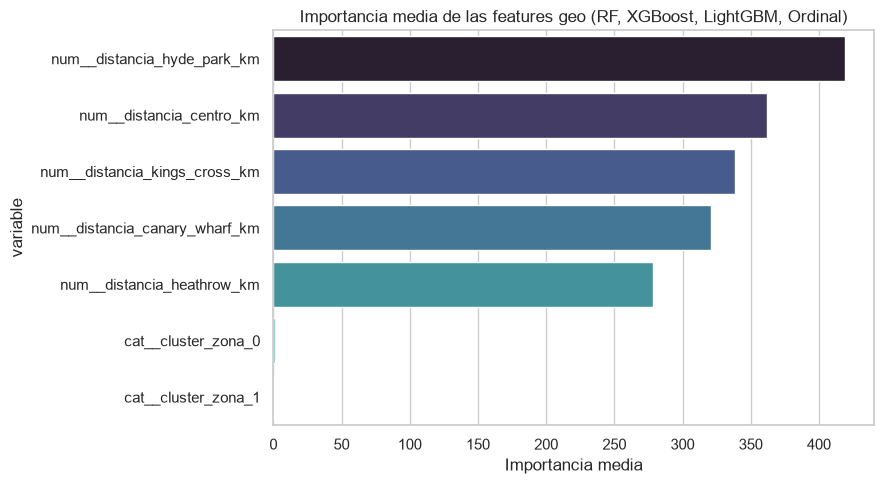

In [8]:
archivos = sorted(REPORTS_DIR.glob('*_features_importancia.csv'))
if not archivos:
    print('No hay archivos de importancia. Ejecuta primero notebooks/models_features/.')
    importancia_agregada = pd.DataFrame(columns=['modelo', 'variable', 'importancia'])
else:
    partes = []
    for ruta in archivos:
        modelo = ruta.stem.replace('_features_importancia', '')
        tabla = pd.read_csv(ruta)
        tabla['modelo'] = modelo
        partes.append(tabla)
    importancia_agregada = pd.concat(partes, ignore_index=True)

if len(importancia_agregada):
    importancia_agregada['es_geo'] = importancia_agregada['variable'].str.contains(
        'distancia_|cluster_zona', regex=True
    )
    resumen_geo = (
        importancia_agregada.groupby(['modelo', 'es_geo'])['importancia']
        .sum()
        .unstack(fill_value=0)
    )
    resumen_geo['aporte_geo_pct'] = (
        resumen_geo.get(True, 0) / resumen_geo.sum(axis=1) * 100
    )
    resumen_geo.to_csv(REPORTS_DIR / 'features_importancia_agregada.csv')
    display(resumen_geo)

    top_geo = (
        importancia_agregada[importancia_agregada['es_geo']]
        .groupby('variable')['importancia']
        .mean()
        .sort_values(ascending=False)
        .head(15)
    )
    plt.figure(figsize=(9, 5))
    sns.barplot(x=top_geo.values, y=top_geo.index, palette='mako')
    plt.title('Importancia media de las features geo (RF, XGBoost, LightGBM, Ordinal)')
    plt.xlabel('Importancia media')
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / 'features_importancia_geo.png', dpi=150, bbox_inches='tight')
    plt.show()

In [9]:
HACER_ABLACION = True
if HACER_ABLACION:
    params = dict(PARAMS_BASE['lightgbm'])

    modelo_con = construir_lgbm_features(X_train, **params)
    modelo_con.fit(X_train, y_train)
    met_con = evaluar_modelo_ordinal(y_val, modelo_con.predict(X_val))

    sin_geo = [c for c in X_train.columns if c not in geo]
    modelo_sin = construir_lgbm_features(X_train[sin_geo], **params)
    modelo_sin.fit(X_train[sin_geo], y_train)
    met_sin = evaluar_modelo_ordinal(y_val, modelo_sin.predict(X_val[sin_geo]))

    ablation = pd.DataFrame(
        [
            {'configuracion': 'sin_geo', 'n_features': len(sin_geo), **{k: v for k, v in met_sin.items() if k != 'matriz_confusion'}},
            {'configuracion': 'con_geo', 'n_features': len(X_train.columns), **{k: v for k, v in met_con.items() if k != 'matriz_confusion'}},
        ]
    )
    ablation['delta_f1_macro'] = ablation['f1_macro'] - ablation.loc[0, 'f1_macro']
    ablation.to_csv(REPORTS_DIR / 'features_ablation_geo.csv', index=False)
    display(ablation)
else:
    print('Ablación omitida.')

,configuracion,n_features,accuracy,balanced_accuracy,f1_macro,f1_weighted,accuracy_adjacent,mae_ordinal,qwk,delta_f1_macro
0,sin_geo,22,0.686790,0.686433,0.685647,0.685959,0.968517,0.348805,0.829750,0.000000
1,con_geo,28,0.686357,0.685982,0.684729,0.685050,0.968841,0.348372,0.831632,-0.000918


,modelo,escenario,n_estimators,learning_rate,num_leaves,accuracy,balanced_accuracy,f1_macro,f1_weighted,accuracy_adjacent,mae_ordinal,qwk,alpha,max_depth,max_features,min_samples_leaf
0,lightgbm_features,geo,100.0,0.1,63.0,0.690577,0.690249,0.689235,0.689510,0.970464,0.345018,0.830026,NaN,NaN,NaN,NaN
1,random_forest_features,geo,100.0,NaN,NaN,0.687006,0.686648,0.684603,0.684894,0.966894,0.352916,0.824071,NaN,NaN,sqrt,1.0
2,xgboost_features,geo,100.0,0.1,NaN,0.679758,0.679409,0.678050,0.678332,0.969274,0.356811,0.824968,NaN,6.0,NaN,NaN
3,ordinal_logistic_features,geo,NaN,NaN,NaN,0.639511,0.639252,0.641959,0.642239,0.969274,0.395759,0.804335,0.1,NaN,NaN,NaN


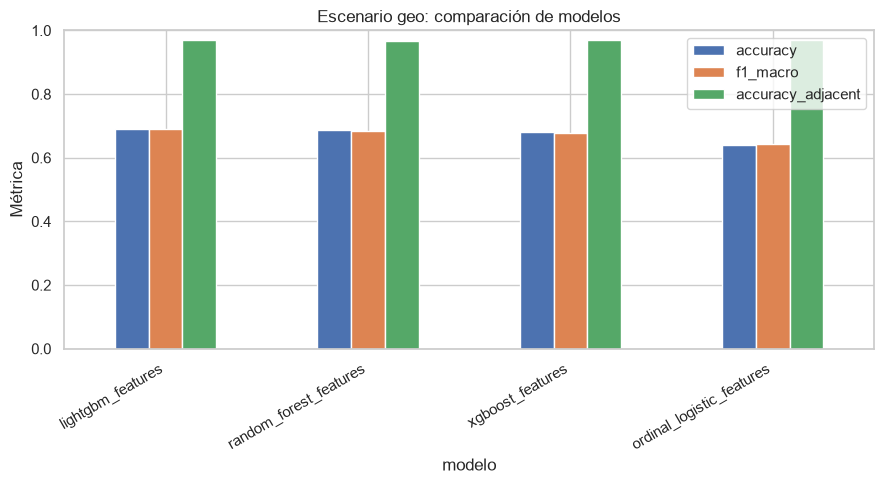

In [10]:
rutas_geo = sorted(REPORTS_DIR.glob('*_features_metricas.csv'))
if rutas_geo:
    geo_df = pd.concat([pd.read_csv(ruta) for ruta in rutas_geo], ignore_index=True)
else:
    print('No hay métricas geo. Ejecuta primero notebooks/models_features/.')
    geo_df = pd.DataFrame()

if len(geo_df):
    geo_df = geo_df.sort_values('f1_macro', ascending=False).reset_index(drop=True)
    geo_df.to_csv(REPORTS_DIR / 'comparacion_features.csv', index=False)
    display(geo_df)

    geo_df.set_index('modelo')[['accuracy', 'f1_macro', 'accuracy_adjacent']].plot(
        kind='bar', figsize=(9, 5)
    )
    plt.title('Escenario geo: comparación de modelos')
    plt.ylabel('Métrica')
    plt.ylim(0, 1)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / 'features_comparacion_modelos.png', dpi=150, bbox_inches='tight')
    plt.show()

escenario,base,geo
modelo,,
lightgbm,0.686526,NaN
lightgbm_features,NaN,0.689235
ordinal_logistic,0.627935,NaN
ordinal_logistic_features,NaN,0.641959
random_forest,0.677917,NaN
random_forest_features,NaN,0.684603
xgboost,0.668548,NaN
xgboost_features,NaN,0.678050


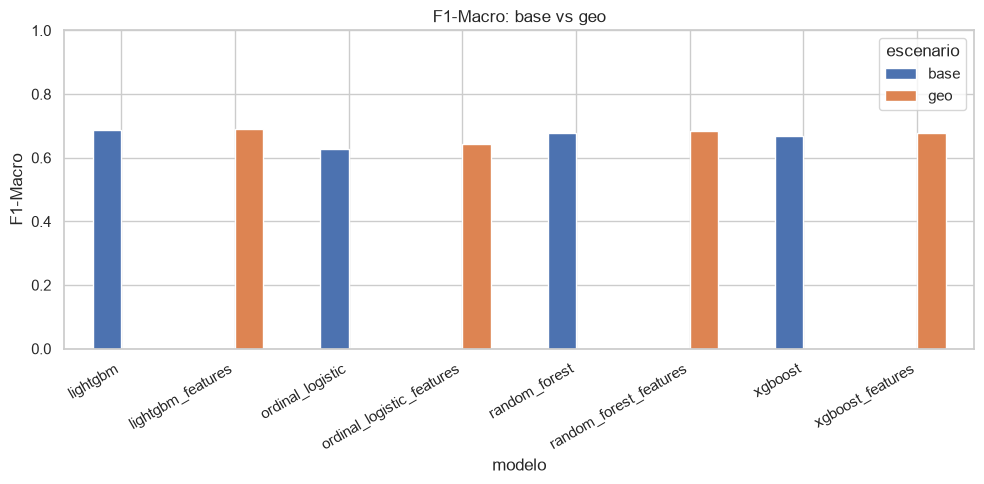

In [11]:
ruta_base = REPORTS_DIR / 'comparacion_base.csv'
if ruta_base.exists() and len(geo_df):
    base_df = pd.read_csv(ruta_base)
    base_df['escenario'] = 'base'
    geo_df['escenario'] = 'geo'
    comparacion = pd.concat([base_df, geo_df], ignore_index=True)
    comparacion.to_csv(REPORTS_DIR / 'comparacion_base_vs_geo.csv', index=False)

    pivot = comparacion.pivot_table(
        index='modelo', columns='escenario', values='f1_macro'
    )
    display(pivot)

    pivot.plot(kind='bar', figsize=(10, 5))
    plt.title('F1-Macro: base vs geo')
    plt.ylabel('F1-Macro')
    plt.ylim(0, 1)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / 'comparacion_base_vs_geo.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Falta comparacion_base.csv o las métricas geo.')

## Interpretación

- **Alineación:** si `clean['id'].equals(feats['id'])` y los tres splits son `True`, la comparación es justa.
- **Aporte geo:** la información mutua suele ser baja porque `latitude`, `longitude` y `neighbourhood_cleansed` ya están en la baseline. Las distancias son transformaciones deterministas de las coordenadas; su valor está en dar al árbol una representación más fácil de partir, no en añadir información nueva.
- **Ablación:** `features_ablation_geo.csv` mide directamente el delta de LightGBM con y sin geo en validación. Si el delta es menor que ±0.005, la mejora no es distinguishable del ruido de un único split.
- **Conclusión esperada:** el escenario geo aporta poco o nada frente a la baseline; el salto grande, si existe, viene del escenario extendido (amenidades, reviews, disponibilidad, densidad).